# P1 Hidden Patch: exploratory data analysis

This notebook shows the train set and the test set. All logic is in `src/eda.py`.

Contents:

1. Labels and distributions of the train set
2. Position of the patches and the decoys (heatmaps)
3. Fifteen train images: one image for each type of case
4. Comparison of the train set and the test set: why are some test images more difficult?
5. Five test images
6. Conclusions

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import eda

pd.set_option("display.width", 140)
df = eda.load_labels()
test_ids = eda.load_test_ids()
print(len(df), "train images,", len(test_ids), "test images")

5000 train images, 5000 test images


## 1. Labels and distributions of the train set

In [2]:
print(df.kind.value_counts().to_string())
print()
print(pd.crosstab(df.attack, df.n_decoys, margins=True))
print()
adv = df[df.kind == "ADV"]
print(adv[["x_min", "y_min", "x_max", "y_max", "w", "h", "area", "strength", "jpeg"]].describe().round(2))

kind
ADV      4000
CLEAN     500
DECOY     500

n_decoys          0     1     2   All
attack                               
cw_l2_u         334   333   333  1000
mifgsm_linf_u   334   333   333  1000
pgd_linf_t      334   333   333  1000
pgd_linf_u      334   333   333  1000
All            1336  1332  1332  4000

         x_min    y_min    x_max    y_max        w        h     area  strength     jpeg
count  4000.00  4000.00  4000.00  4000.00  4000.00  4000.00  4000.00   4000.00  4000.00
mean     21.41    36.46    42.38    58.99    20.98    22.54     0.11     10.32    92.54
std      15.21     3.95    15.28     4.20     4.65     4.70     0.02      5.88     1.71
min       0.00    32.00    13.00    45.00    13.00    13.00     0.08      1.30    90.00
25%       6.00    33.00    29.00    56.00    17.00    19.00     0.10      6.00    91.00
50%      22.00    36.00    42.00    60.00    20.00    23.00     0.11     10.00    93.00
75%      35.00    39.00    58.00    62.00    24.00    26.00     0.13 

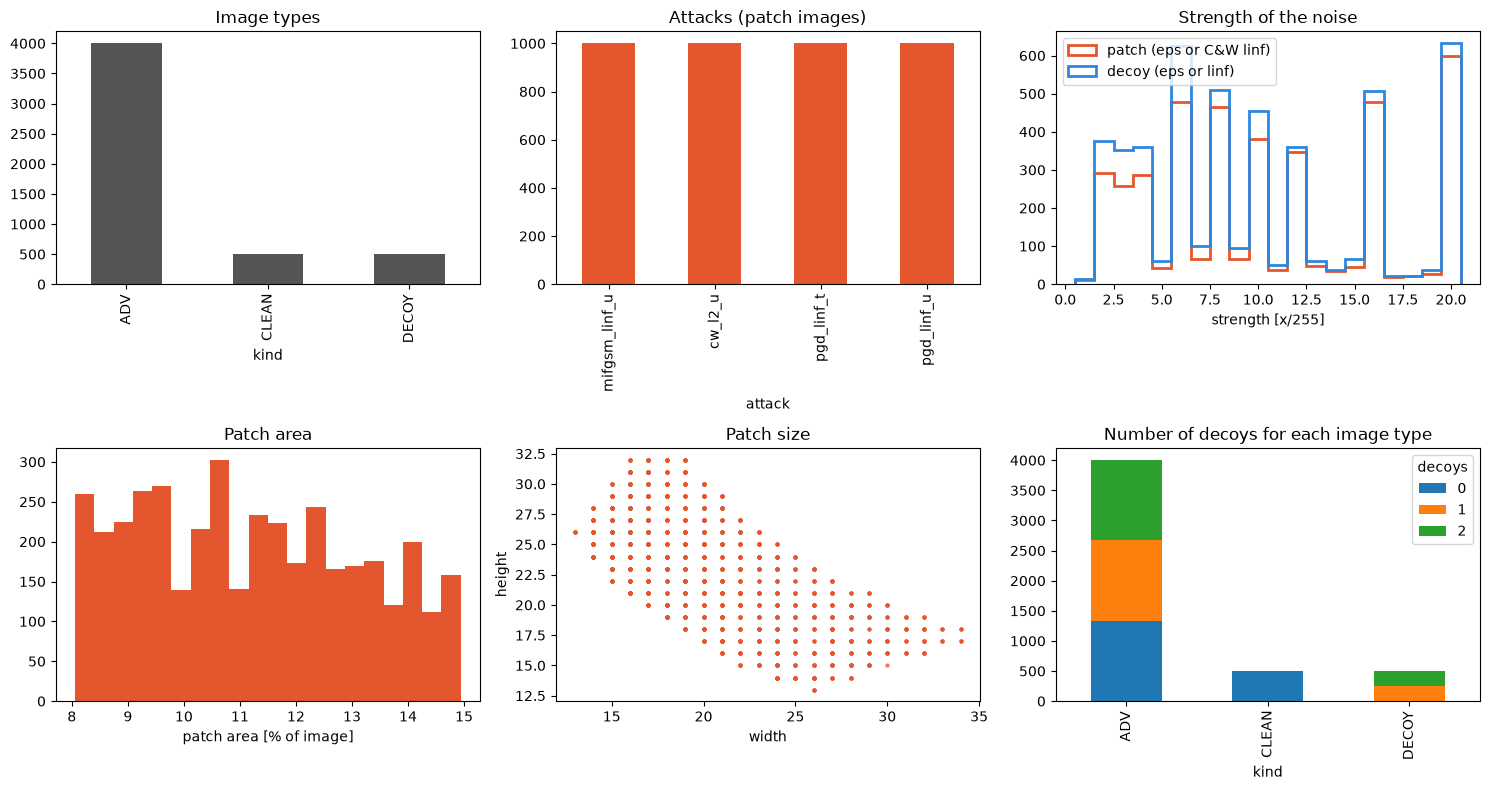

In [3]:
eda.plot_distributions(df);

The data agrees with the task text:

- 80% patch, 10% decoys only, 10% clean. Each attack has 1000 images.
- One third of the patch images has no decoy, one third has 1 decoy, one third has 2 decoys.
- The strength of the patches and of the decoys has the same distribution (2/255 to 20/255).
- The patch area is 8-15% of the image. The width and the height are from 13 to 34 pixels.
- The JPEG quality is from 90 to 95 with equal shares.

## 2. Position of the patches and the decoys

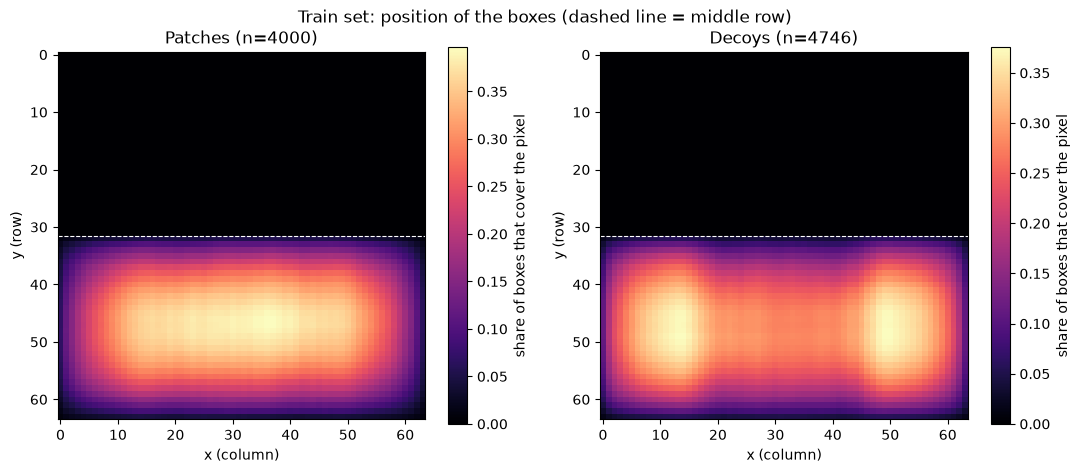

In [4]:
eda.plot_position_heatmaps(df);

patch y_min: min 32  max 51
decoy y_min: min 32  max 51


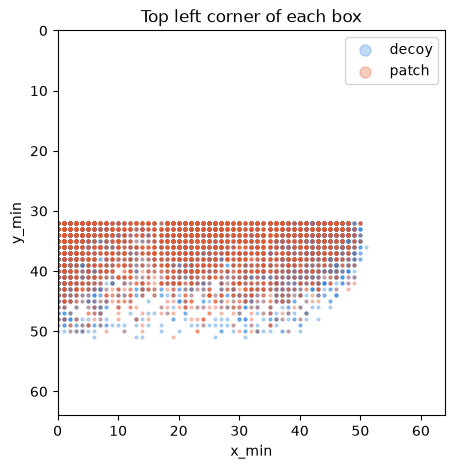

In [5]:
eda.plot_box_corners(df)
decoy_boxes = pd.DataFrame([d["box"] for ds in df.decoys for d in ds], columns=["x_min", "y_min", "x_max", "y_max"])
print("patch y_min: min", adv.y_min.min(), " max", adv.y_min.max())
print("decoy y_min: min", decoy_boxes.y_min.min(), " max", decoy_boxes.y_min.max())

**All patches and all decoys in the train set are in the bottom half of the image (y_min ≥ 32).**
The top half never has a box.
The decoys are usually on the left or on the right of the patch, because the boxes do not overlap.

## 3. Fifteen train images

Left column: the original image. Right column: the amplified residual (image minus its 3x3 median), with the true boxes.
The residual shows the high-frequency noise. The noise is not visible in the original image.

- Red box: the patch (the adversarial attack).
- Blue box: a decoy (random noise).

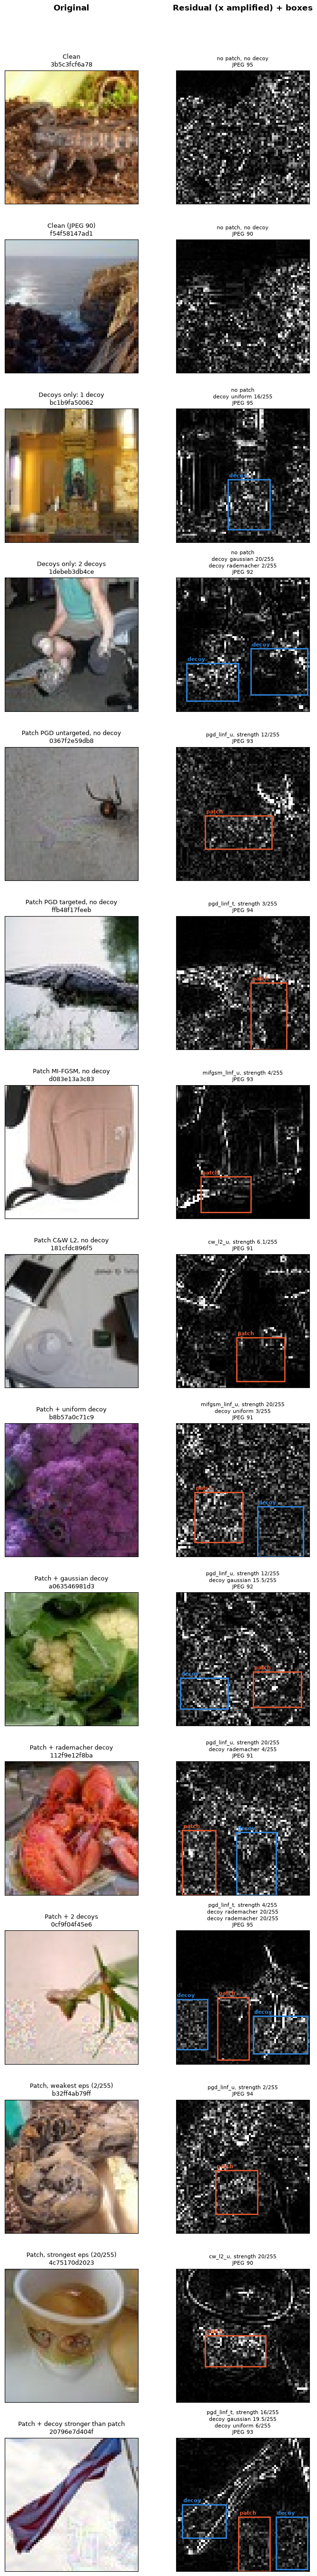

In [6]:
cases = eda.pick_train_cases(df)
eda.plot_train_cases(df, cases);

## 4. Train set and test set: why are some test images more difficult?

The test set has no labels. Thus we compare the two sets with two methods that need no labels.

**Method 1: residual energy for each row band.** It shows where the high-frequency noise is.

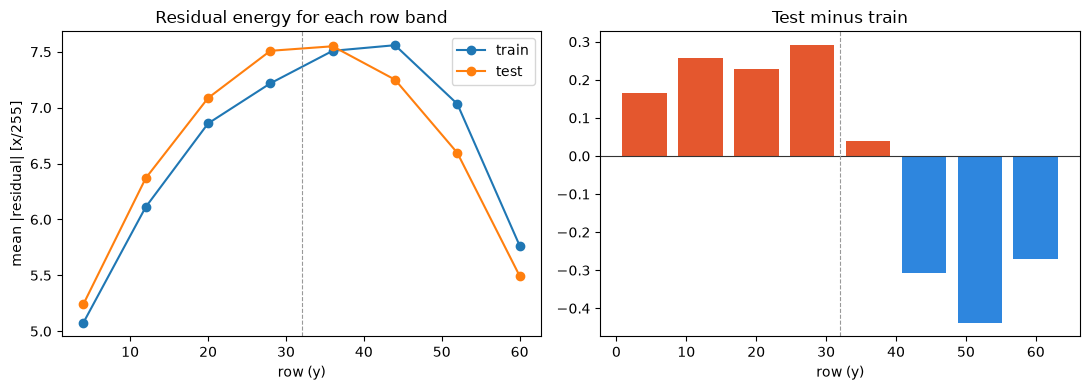

In [7]:
train_images = eda.load_images("train", df.id)
test_images = eda.load_images("test", test_ids)
eda.plot_train_test_profiles(train_images, test_images);

The test set has more noise in the top half and less noise in the bottom half.
This signal is weak, because the image content also has high-frequency parts.

**Method 2: smooth one half of the image.** A 3x3 median removes the adversarial noise.
If the smoothing of only one half changes the predicted class, then that half most probably holds the patch.
We use a random sample of 3000 images from each set to keep the run short on the CPU.

             train  test
region                  
top only       5.0  26.0
bottom only   51.4  25.7
both          22.2  25.7
none          21.4  22.6


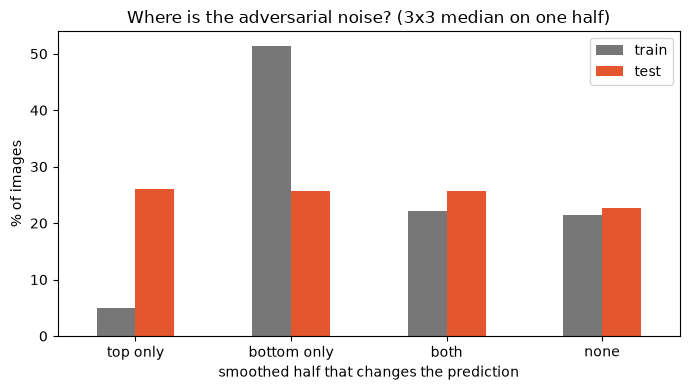

In [8]:
model = eda.load_model()
rng = np.random.default_rng(0)
train_idx = rng.choice(len(df), 3000, replace=False)
test_idx = rng.choice(len(test_ids), 3000, replace=False)
train_flips = eda.half_flips(model, train_images[train_idx])
test_flips = eda.half_flips(model, test_images[test_idx])
fig, table = eda.plot_half_flips(train_flips, test_flips)
print((table * 100).round(1))

In [9]:
# Check on the train labels: does the method find the half with the patch?
table = pd.crosstab(
    df.kind.values[train_idx], train_flips.region.values,
    rownames=["image type"], colnames=["smoothed half that changes the prediction"], normalize="index",
)[["top only", "bottom only", "both", "none"]]
print((table * 100).round(1))

smoothed half that changes the prediction  top only  bottom only  both  none
image type                                                                  
ADV                                             4.4         61.8  26.7   7.0
CLEAN                                           7.2         12.1   2.3  78.4
DECOY                                           8.2          4.3   4.3  83.2


## 5. Five test images

We take two images where only the smoothing of the top half changes the prediction,
two images where only the bottom half does it, and one image where no half does it.
The yellow dashed line is the middle row.

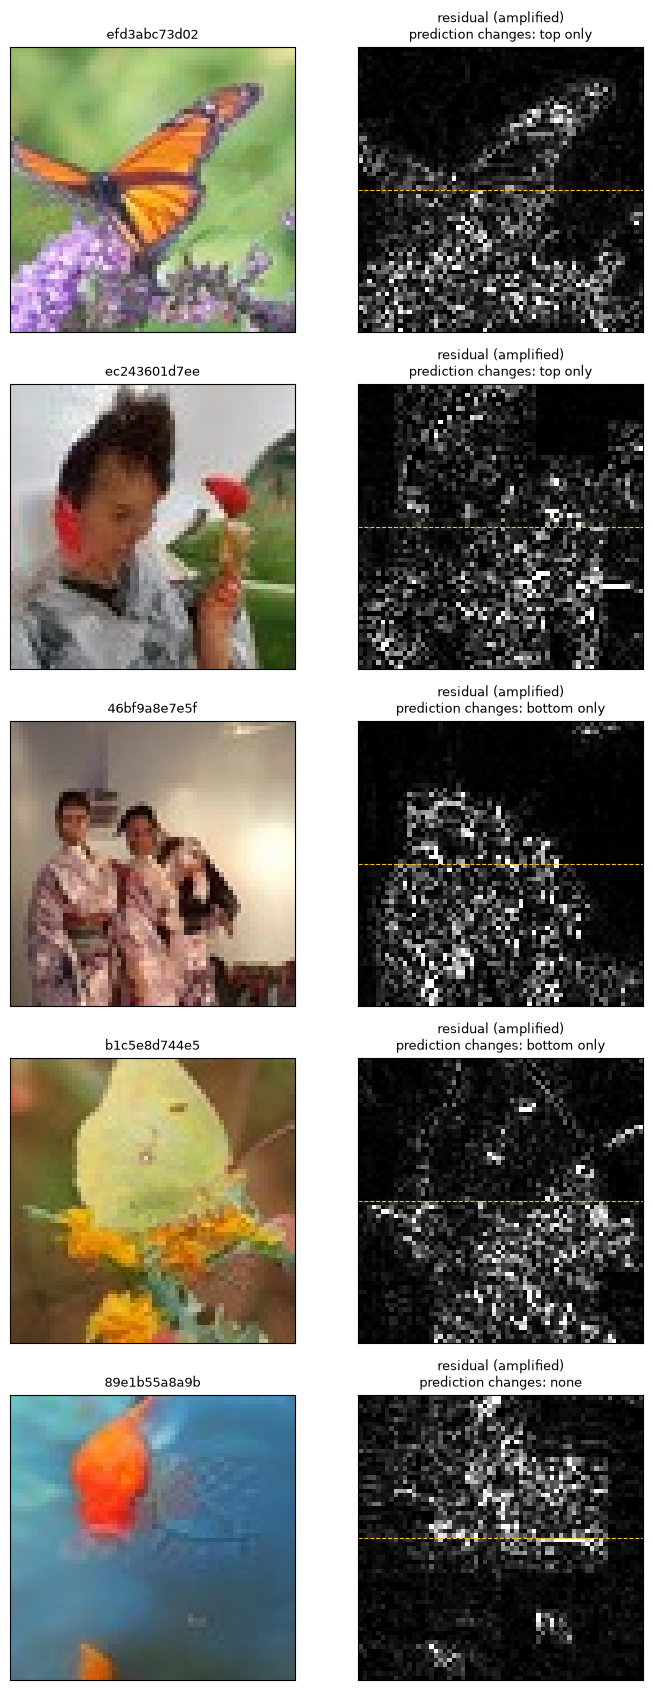

In [10]:
sample = pd.DataFrame({"id": test_ids.values[test_idx], "region": test_flips.region.values})
picks = pd.concat([
    sample[sample.region == "top only"].sample(2, random_state=1),
    sample[sample.region == "bottom only"].sample(2, random_state=1),
    sample[sample.region == "none"].sample(1, random_state=1),
])
eda.plot_test_cases(picks.id.tolist(), [f"prediction changes: {r}" for r in picks.region]);

## 6. Conclusions

1. **Train set:** all patches and all decoys are in the bottom half of the image (y_min from 32 to 51). The top half never has a box.
2. **Test set:** the smoothing of only the top half changes the prediction for 26.0% of the test images, but for only 5.0% of the train images. The smoothing of only the bottom half changes it for 25.7% of the test images and for 51.4% of the train images.
3. Thus approximately half of the test patches are probably in the top half. A method that learns the position from the train set fails on these images. This is the most probable reason why "some test images are more difficult".
4. The residual energy of the test set also moves to the top half. This agrees with point 3.
5. The smoothing of the full image changes the prediction for approximately 73% of the images in both sets. The share of images with no change ("none") is also almost the same. Thus the strength of the attacks and the share of clean images are probably the same in the two sets.
6. The half-smoothing test is also a simple detector. On the train set, it gives "none" for 78-83% of the clean and decoy images, but for only 7% of the patch images.

Consequences for training:

- Do not use the position of the train boxes as prior knowledge.
- Apply the augmentation during training, not as extra copies of the images. Each epoch then shows a different variant of each image.
- Use a vertical flip with p = 0.5. It puts approximately half of the patches in the top half, as in the test set.
- Use a horizontal flip with p = 0.5 for more variety.
- Apply the flips to all images, also to the clean images and the decoy images. Else the model can learn that a flip means a patch.
- Change the boxes of the patch and of the decoys with the image:
  - horizontal flip: x_min = 64 - x_max, x_max = 64 - x_min;
  - vertical flip: y_min = 64 - y_max, y_max = 64 - y_min.
- Keep the box 0,0,0,0 unchanged for images without a patch.
- Fix the seed of each random step, so that each experiment is reproducible.
- Do not use shifts or crops. They move the boxes and break the 8x8 JPEG grid.
- Do not change colors, add noise, blur or recompress the images. These changes destroy the weak signal of the patches and of the decoys.

Open points:

- A flipped patch possibly does not change the prediction of ResNet-18. This is important only for a detector that uses ResNet-18 features. The true class in `comment` (true=...) lets us check it.
- Other differences in the test set (for example a lower JPEG quality or a smaller eps) are possible. This EDA does not show them.